## Que 1.
The delivery_time.csv dataset contains information about Delivery time and Sorting Time. 
We have to prepare Polynomial regression model to predict Sorting time on the basis of Delivery Time. 


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("delivery_time.csv")
df.head()

,Delivery Time,Sorting Time
0,21.00,10
1,13.50,4
2,19.75,6
3,24.00,9
4,29.00,10


In [3]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Delivery Time  21 non-null     float64
 1   Sorting Time   21 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 464.0 bytes


In [4]:
df.describe() 

,Delivery Time,Sorting Time
count,21.000000,21.000000
mean,16.790952,6.190476
std,5.074901,2.542028
min,8.000000,2.000000
25%,13.500000,4.000000
50%,17.830000,6.000000
75%,19.750000,8.000000
max,29.000000,10.000000


In [5]:
df.head()

,Delivery Time,Sorting Time
0,21.00,10
1,13.50,4
2,19.75,6
3,24.00,9
4,29.00,10


In [6]:
df.corr()  

,Delivery Time,Sorting Time
Delivery Time,1.000000,0.825997
Sorting Time,0.825997,1.000000


<Axes: >

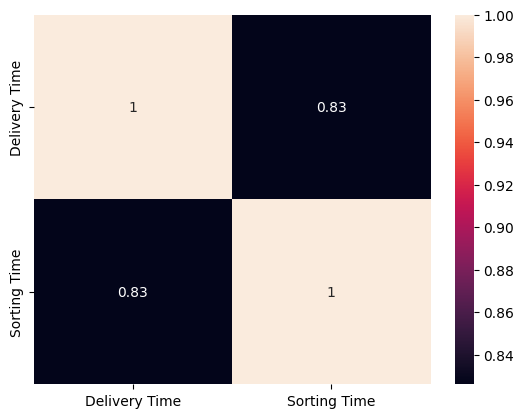

In [7]:
sns.heatmap(df.corr(),annot=True)

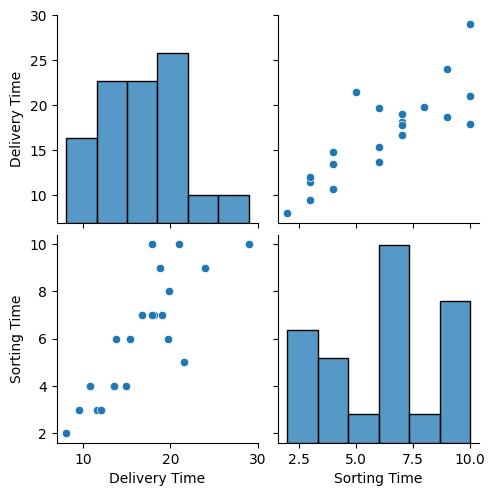

In [10]:
sns.pairplot(df)

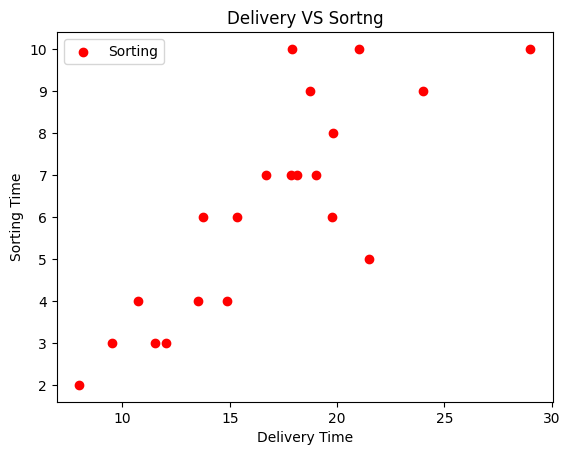

In [12]:
plt.scatter(df['Delivery Time'],df['Sorting Time'],color="red",label="Sorting")
plt.title("Delivery VS Sortng")
plt.xlabel("Delivery Time")
plt.ylabel("Sorting Time")
plt.legend()

In [13]:
X=df.drop('Sorting Time',axis=1)
y=df['Sorting Time']

In [14]:
X

,Delivery Time
0,21.00
1,13.50
2,19.75
3,24.00
4,29.00
5,15.35
6,19.00
7,9.50
8,17.90
9,18.75


In [16]:
from sklearn.preprocessing import PolynomialFeatures
polynomial_terms=PolynomialFeatures(degree=2)
preprocessed_X=polynomial_terms.fit_transform(X)
preprocessed_X

array([[  1.    ,  21.    , 441.    ],
       [  1.    ,  13.5   , 182.25  ],
       [  1.    ,  19.75  , 390.0625],
       [  1.    ,  24.    , 576.    ],
       [  1.    ,  29.    , 841.    ],
       [  1.    ,  15.35  , 235.6225],
       [  1.    ,  19.    , 361.    ],
       [  1.    ,   9.5   ,  90.25  ],
       [  1.    ,  17.9   , 320.41  ],
       [  1.    ,  18.75  , 351.5625],
       [  1.    ,  19.83  , 393.2289],
       [  1.    ,  10.75  , 115.5625],
       [  1.    ,  16.68  , 278.2224],
       [  1.    ,  11.5   , 132.25  ],
       [  1.    ,  12.03  , 144.7209],
       [  1.    ,  14.88  , 221.4144],
       [  1.    ,  13.75  , 189.0625],
       [  1.    ,  18.11  , 327.9721],
       [  1.    ,   8.    ,  64.    ],
       [  1.    ,  17.83  , 317.9089],
       [  1.    ,  21.5   , 462.25  ]])

In [28]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    preprocessed_X, y,train_size=0.7,random_state=42)

In [29]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [30]:
y_pred=model.predict(X_test)

In [31]:
from sklearn.metrics import mean_absolute_error
mae=mean_absolute_error(y_test,y_pred)
print(f"mean absolut error={mae:.2f}")

mean absolut error=1.29


In [32]:
from sklearn.metrics import mean_absolute_percentage_error
mape=mean_absolute_percentage_error(y_test,y_pred)
print(f"mean aboslute percentage error={mape:.2f}")

mean aboslute percentage error=0.19


In [33]:
from sklearn.metrics import mean_squared_error
mse=mean_squared_error(y_test,y_pred)
print(f"mean squared error={mse:.2f}")

mean squared error=2.80


In [34]:
from sklearn.metrics import mean_squared_log_error
msle=mean_squared_log_error(y_test,y_pred)
print(f"mean squared log error={msle:.2f}")

mean squared log error=0.04


In [35]:
from sklearn.metrics import root_mean_squared_log_error
rmsle=root_mean_squared_log_error(y_test,y_pred)
print(f"root mean squared log error={rmsle:.2f}")

root mean squared log error=0.20


In [36]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred) 
print(f"R-squared value={r2:.2f}")

R-squared value=0.55


In [37]:
n = y_test.size    # no of records
p = 3              # no of features
adjusted_r2 = 1 - ((1 - r2) * ((n - 1) / (n - p - 1)))
print(f"Adjusted r2={adjusted_r2}")

Adjusted r2=0.10390129334930132


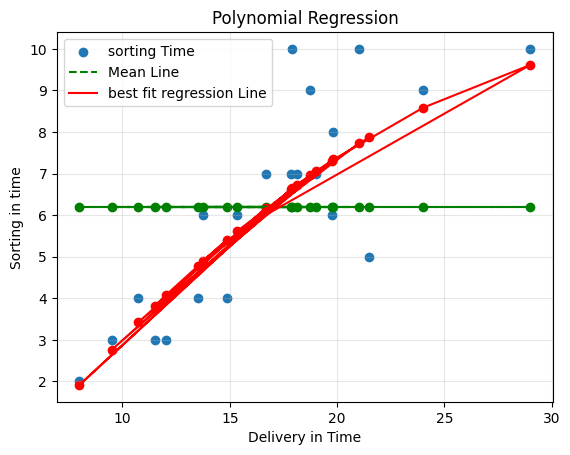

In [41]:
y_pred=model.predict(preprocessed_X)
plt.scatter(df['Delivery Time'],y , label="sorting Time")

mean_values=np.ones(y.size)*y.mean()
plt.scatter(df['Delivery Time'],mean_values,color="green")
plt.plot(df['Delivery Time'],mean_values,color="green",linestyle="--",label="Mean Line")

plt.scatter(df['Delivery Time'],y_pred,color="red")
plt.plot(df['Delivery Time'],y_pred,color="red",label="best fit regression Line")
# plt.plot(X_test['Delivery Time'],y_pred,color="red",label="egression Line")
# plt.scatter(X_test['Delivery Time'],y_pred,color="red",marker="s")
plt.title("Polynomial Regression")
plt.xlabel("Delivery in Time")
plt.ylabel("Sorting in time")
plt.legend()
plt.grid(visible=True,alpha=0.3)

In [43]:
model.intercept_

-3.3438730402377814

In [44]:
model.coef_

array([ 0.        ,  0.73748353, -0.01002017])